# FreeMol-Gen

我們自己設計的基於Transformer-Decoder架構

AI自由藥物生成器



In [ ]:
!pip install rdkit -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.7/36.7 MB 43.3 MB/s eta 0:00:00


In [ ]:
import os
import math
import platform
import rdkit
import IPython
import json
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from google.colab import drive
from tensorflow.keras import layers
from tensorflow.keras.utils import plot_model
from rdkit import Chem
from rdkit.Chem import Draw

In [ ]:
# 1. 掛載雲端硬碟與複製到虛擬機的本地端
drive.mount('/content/drive')
input_file_path = '/content/drive/MyDrive/MD_and_CADD/smiles_and_properties.csv'
local_file_path = '/content/smiles_and_properties.csv'
shutil.copy(input_file_path, local_file_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


'/content/smiles_and_properties.csv'

In [ ]:
# 2. 讀取檔案
df = pd.read_csv(local_file_path)
all_smiles = df['SMILES']

print(f"總共讀取了 {len(all_smiles)} 筆分子資料")

總共讀取了 249455 筆分子資料


In [ ]:
# 3. 定義特殊 Token 與詞彙表
BEGIN_TOKEN = "[BEGIN]"
END_TOKEN = "[END]"
PAD_TOKEN = "[PAD]"

## 從所有資料中提取所有出現過的字元
unique_chars = sorted(list(set("".join(all_smiles))))
vocab = [PAD_TOKEN, BEGIN_TOKEN, END_TOKEN] + unique_chars
char_to_id = {c: i for i, c in enumerate(vocab)}
id_to_char = {i: c for i, c in enumerate(vocab)}
vocab_size = len(vocab)

## 定義輸入字串預留長度
## 找出最長的藥物名稱+[BEGIN]和[END]，並進行2的冪次方對齊
max_seq_len = 2 ** math.ceil(math.log2(len(max(all_smiles, key=len))+2))


## 進行Padding
def encode_all(smiles_list):
    encoded_list = []
    for s in smiles_list:
        tokens = [BEGIN_TOKEN] + list(s) + [END_TOKEN]
        ids = [char_to_id[t] for t in tokens]
        # Padding 到統一長度 102
        ids += [char_to_id[PAD_TOKEN]] * (max_seq_len - len(ids))
        encoded_list.append(ids)
    return np.array(encoded_list)

X_data = encode_all(all_smiles)

print(f"詞彙表大小: {vocab_size}")
print(f"資料矩陣形狀: {X_data.shape}")


詞彙表大小: 37
資料矩陣形狀: (249455, 128)


In [ ]:
# --- A. 定義 Transformer 核心組件 ---

@tf.keras.utils.register_keras_serializable()
class TransformerBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1, use_causal_mask=False, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim, self.num_heads, self.ff_dim, self.rate = embed_dim, num_heads, ff_dim, rate
        self.use_causal_mask = use_causal_mask
        self.supports_masking = True
        self.att = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = tf.keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim),
        ])
        self.layernorm1 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = layers.Dropout(rate)
        self.dropout2 = layers.Dropout(rate)

    def call(self, inputs, training=None, mask=None):
        attn_output = self.att(inputs, inputs, attention_mask=mask, use_causal_mask=self.use_causal_mask)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

    def get_config(self): # 必須要有這個，別台機器才載入得了
        config = super().get_config()
        config.update({
            "embed_dim": self.embed_dim, "num_heads": self.num_heads,
            "ff_dim": self.ff_dim, "rate": self.rate, "use_causal_mask": self.use_causal_mask
        })
        return config

@tf.keras.utils.register_keras_serializable()
class TokenAndPositionEmbedding(layers.Layer):
    def __init__(self, max_len, vocab_size, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.max_len, self.vocab_size, self.embed_dim = max_len, vocab_size, embed_dim
        self.token_emb = layers.Embedding(input_dim=vocab_size, output_dim=embed_dim)
        self.pos_emb = layers.Embedding(input_dim=max_len, output_dim=embed_dim)

    def call(self, x):
        maxlen = tf.shape(x)[-1]
        positions = tf.range(start=0, limit=maxlen, delta=1)
        return self.token_emb(x) + self.pos_emb(positions)

    def get_config(self):
        config = super().get_config()
        config.update({"max_len": self.max_len, "vocab_size": self.vocab_size, "embed_dim": self.embed_dim})
        return config

# --- B. 建立 GPT 模型生成器 ---

def create_drug_gpt(max_len, vocab_size, embed_dim, num_heads, ff_dim, num_layers=2):
    inputs = layers.Input(shape=(max_len,))

    # 嵌入與位置編碼
    x = TokenAndPositionEmbedding(max_len, vocab_size, embed_dim)(inputs)

    # 修正：移除手動建立的 Causal Mask，改用 MultiHeadAttention 內建功能
    # mask = tf.linalg.band_part(tf.ones((max_len, max_len)), -1, 0)
    # mask = tf.cast(mask, tf.bool)
    # mask = mask[tf.newaxis, tf.newaxis, :, :]

    # 堆疊 Transformer 層
    for _ in range(num_layers):
        # 傳遞 use_causal_mask=True 給 TransformerBlock
        x = TransformerBlock(embed_dim, num_heads, ff_dim, use_causal_mask=True)(x)

    # 輸出層 (Softmax 預測詞彙機率)
    outputs = layers.Dense(vocab_size, activation="softmax")(x)

    return tf.keras.Model(inputs=inputs, outputs=outputs)

In [ ]:
# --- C. 資料準備與模型實例化 ---

# 確保 X_train / Y_train 的長度正確 (長度應為 max_seq_len - 1)
X_train = X_data[:, :-1]
Y_train = X_data[:, 1:]
current_seq_len = X_train.shape[1]

print(f"訓練輸入形狀: {X_train.shape}") # 預計為 (N, max_seq_len - 1)
print(f"訓練目標形狀: {Y_train.shape}") # 預計為 (N, max_seq_len - 1)

# 初始化模型
model = create_drug_gpt(
    max_len=current_seq_len,
    vocab_size=vocab_size,
    embed_dim=128,
    num_heads=4,
    ff_dim=256,
    num_layers=4
)

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
model.summary()

訓練輸入形狀: (249455, 127)
訓練目標形狀: (249455, 127)


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 127)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ token_and_position_embedding    │ (None, 127, 128)       │        20,992 │
│ (TokenAndPositionEmbedding)     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ (None, 127, 128)       │       330,240 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ (None, 127, 128)       │       330,240 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_2             │ (None, 127, 128)       │       330,240 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_3             │ (None, 127, 128)       │       330,240 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 127, 37)        │         4,773 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,346,725 (5.14 MB)

 Trainable params: 1,346,725 (5.14 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# --- D. 開始訓練 (Fitting) ---

history = model.fit(
    X_train,
    Y_train,
    epochs=50,
    batch_size=256,
    validation_split=0.1
)

Epoch 1/50
877/877 ━━━━━━━━━━━━━━━━━━━━ 218s 220ms/step - loss: 0.3600 - val_loss: 0.2623
Epoch 2/50
877/877 ━━━━━━━━━━━━━━━━━━━━ 188s 215ms/step - loss: 0.2605 - val_loss: 0.2379
Epoch 3/50
877/877 ━━━━━━━━━━━━━━━━━━━━ 187s 213ms/step - loss: 0.2421 - val_loss: 0.2280
Epoch 4/50
877/877 ━━━━━━━━━━━━━━━━━━━━ 187s 214ms/step - loss: 0.2327 - val_loss: 0.2209
Epoch 5/50
877/877 ━━━━━━━━━━━━━━━━━━━━ 187s 214ms/step - loss: 0.2284 - val_loss: 0.2163
Epoch 6/50
877/877 ━━━━━━━━━━━━━━━━━━━━ 188s 215ms/step - loss: 0.2221 - val_loss: 0.2132
Epoch 7/50
877/877 ━━━━━━━━━━━━━━━━━━━━ 202s 215ms/step - loss: 0.2204 - val_loss: 0.2108
Epoch 8/50
877/877 ━━━━━━━━━━━━━━━━━━━━ 187s 213ms/step - loss: 0.2162 - val_loss: 0.2086
Epoch 9/50
877/877 ━━━━━━━━━━━━━━━━━━━━ 187s 213ms/step - loss: 0.2148 - val_loss: 0.2066
Epoch 10/50
877/877 ━━━━━━━━━━━━━━━━━━━━ 187s 213ms/step - loss: 0.2130 - val_loss: 0.2045
Epoch 11/50
877/877 ━━━━━━━━━━━━━━━━━━━━ 187s 213ms/step - loss: 0.2107 - val_loss: 0.2034
Epoch 12

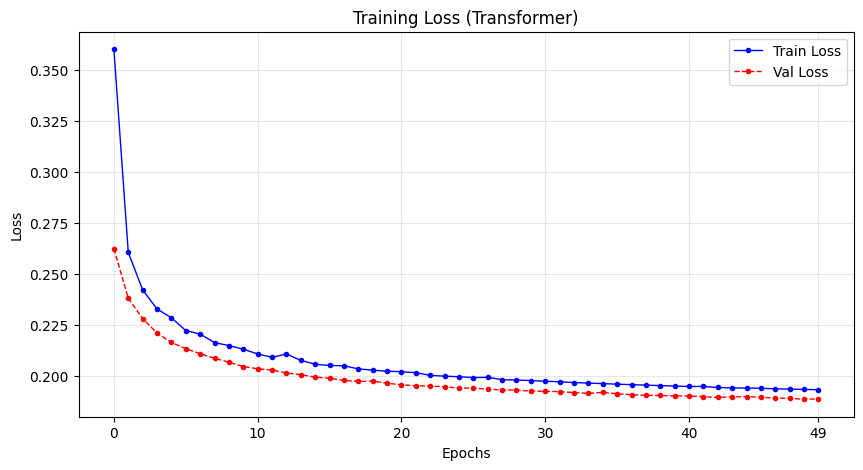

In [ ]:
import matplotlib.pyplot as plt

def plot_final_loss(history):
    loss = history.history['loss']
    val_loss = history.history.get('val_loss', [])
    epochs = range(len(loss))

    plt.figure(figsize=(10, 5))

    # 1. 繪製曲線：不設定 markevery，點就會很密
    plt.plot(epochs, loss, 'bo-', label='Train Loss', markersize=3, linewidth=1)
    if val_loss:
        plt.plot(epochs, val_loss, 'ro--', label='Val Loss', markersize=3, linewidth=1)

    # 2. 精簡 X 軸：只顯示 0, 10, 20... 與最後一格
    ticks = list(range(0, len(loss), 10))
    if (len(loss) - 1) not in ticks:
        ticks.append(len(loss) - 1)

    plt.xticks(ticks)

    # 3. 必要美化
    plt.title('Training Loss (Transformer)')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_final_loss(history)

 AI 藥物設計中 (使用溫度採樣)...
#01: CCc1ccc(C(=O)N2C[C@]3(CCCN(C(=O)c4c(C)c[nH]c4C)C3)CC[C@H]2C)s1 (合法)
#02: C[C@@H]1CCCC[C@@H]1N(C)C(=O)C1CCN(S(C)(=O)=O)CC1 (合法)
#03: CC(C)[C@@H](C(=O)Nc1ccc2c(c1)OCO2)/C(N)=N\O (合法)
#04: CCC(O)(C)NC(=O)c1ccccc1NC(=O)c1ccccc1 (合法)
#05: O=S(=O)(c1ccccc1)N1CCC[C@H](CC(=O)[O-])C1 (合法)
#06: COCCCn1nc(C(=O)N2CC[C@H]3[C@@H](CCC[NH+]3C)C2)c2ccccc2c1=O (合法)
#07: CCS(=O)(=O)c1ccc(/C=C(\C#N)C(=O)N[C@@H](C)c2ccc(Cl)c(Cl)c2)cc1 (合法)
#08: CC(C)N(C(=O)C(=O)Nc1ccc2c(c1)OCCO2)c1ccccc1Cl (合法)
#09: Cc1c(C(=O)N2CCN(C(=O)[C@H]3C[C@@H]3C(=O)c3cccc(F)c3)CC2)c(C)nn1C (合法)
#10: CC(=O)N(C)c1cccc(NC(=O)c2c(F)cccc2Cl)c1 (合法)
#11: CC(=O)c1ccc(NC(=O)[C@H]2CCCN2C(C)=O)cc1F (合法)
#12: CCN1C[C@H](COC(=O)c2cc(-c3ccccc3Br)on2)CC1=O (合法)
#13: O=C(Nc1cccnc1-n1cccn1)c1cn(C2CCCC2)nn1 (合法)
#14: O=C(CCOc1ccc2c(c1)OCO2)NNC(=O)c1cccs1 (合法)
#15: Cc1cc(C)nc(-n2ncc(C(=O)N3CC[C@H](C#N)[C@@H]3C)c2C2CC2)n1 (合法)
#16: C[C@H](NC(=O)c1ccccc1N1C(=O)/C(=C/c2ccc(N3CCOCC3)cc2)SC1=S)c1ccccc1 (合法)
#17: CC(=O)c1c(C)cc(C

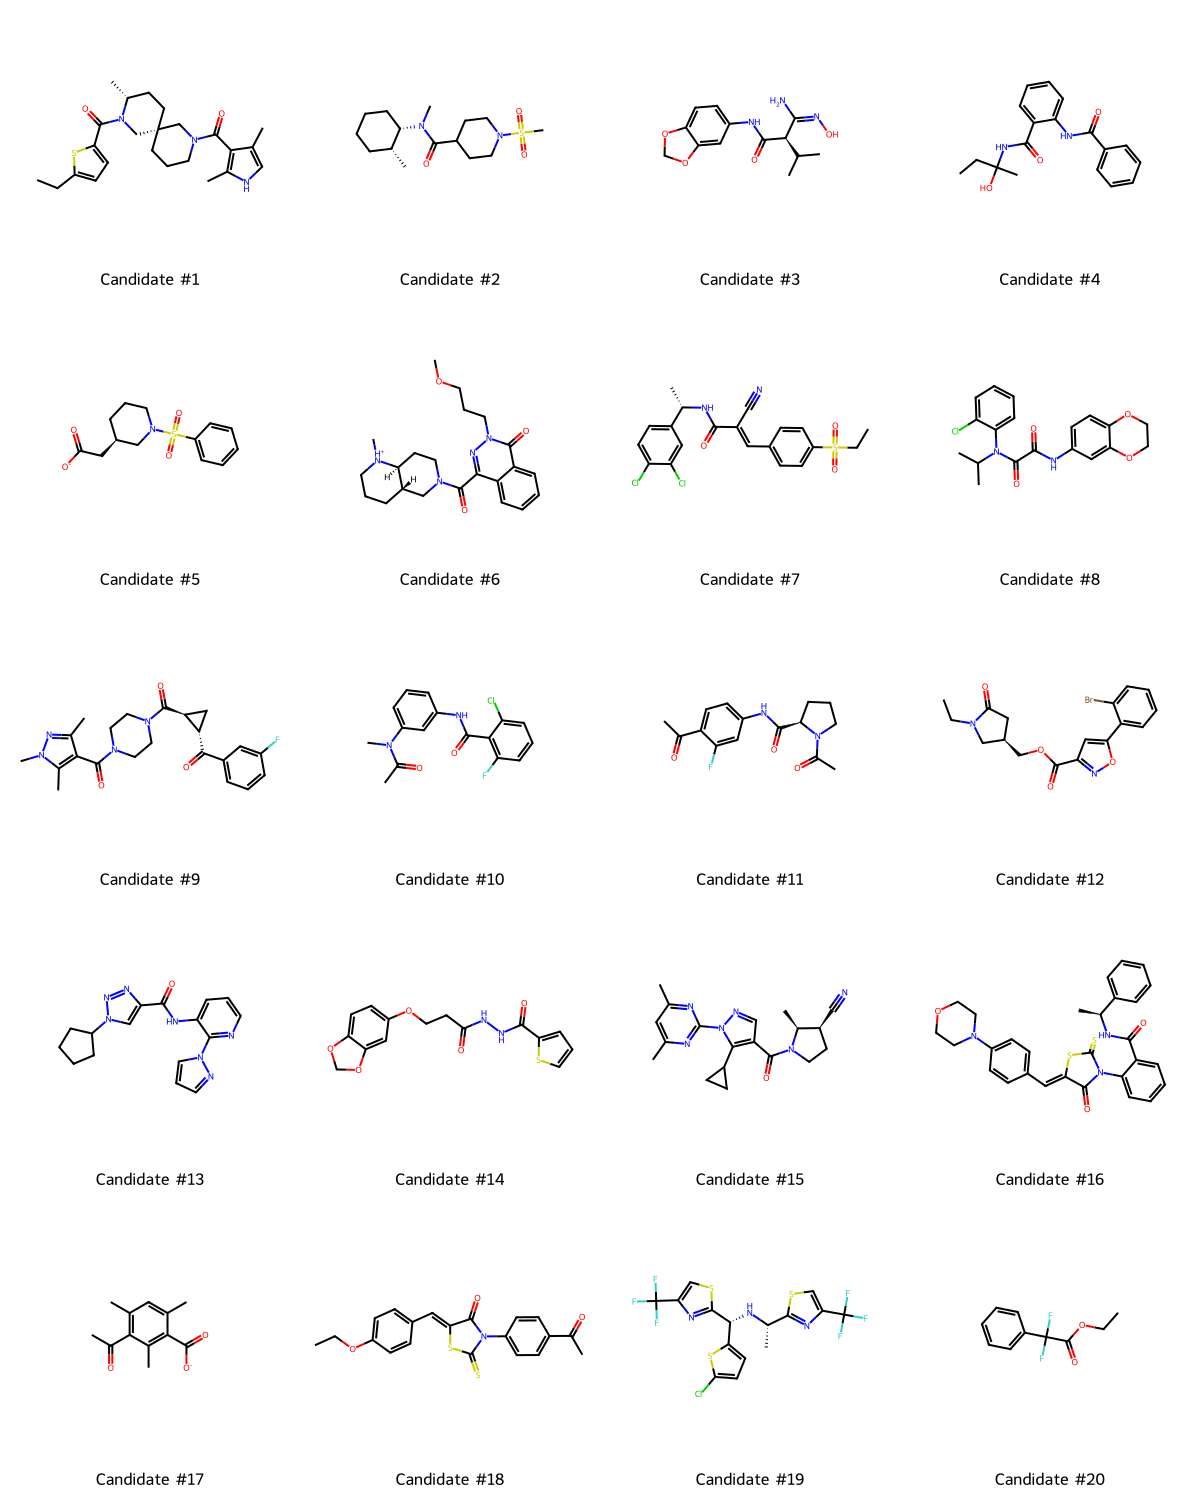

In [ ]:
# --- E. 推理與驗證 ---
def generate_drug_candidate(model, char_to_id, id_to_char, target_len=model.input_shape[1], temperature=1.0):
    """
    這是一個完整的 Transformer Decoder 推理流程 (Inference Pipeline)。
    透過溫度採樣讓生成的分子具備多樣性。
    """
    # 1. Decoder 起始：從 [BEGIN] 開始
    generated_ids = [char_to_id["[BEGIN]"]]
    pad_id = char_to_id["[PAD]"]

    # 開始 Autoregressive (自回歸) 循環生成
    for i in range(target_len - 1):
        # 2. 準備輸入張量 (對齊維度至max_seq_len - 1)
        # 對應 Decoder 的 Input：已生成的 Tokens + Padding
        current_len = len(generated_ids)
        needed_pad = target_len - current_len
        input_seq = np.array([generated_ids + [pad_id] * needed_pad])

        # 3. 前向傳播 (Forward Pass)
        # 模型輸出所有位置的機率分佈
        predictions = model.predict(input_seq, verbose=0)

        # 4. 提取當前位置的 Logits (對應最後一個非 PAD 原子的輸出)
        # 對應 Decoder 的 Output Linear 層
        logits = predictions[0, current_len - 1, :]

        # 5. 溫度採樣 (Temperature Sampling)
        # 調整機率分佈的平滑度：T 越高越隨機，T 越低越保守
        logits = np.log(logits + 1e-10) / temperature
        exp_logits = np.exp(logits)
        probs = exp_logits / np.sum(exp_logits)

        # 根據機率隨機選擇下一個 Token
        next_token_id = np.random.choice(len(probs), p=probs)

        # 6. 終止判斷：如果抽到 [END] 則結束生成
        if next_token_id == char_to_id["[END]"]:
            break

        generated_ids.append(next_token_id)

    # 7. 解碼：跳過開頭的 [BEGIN]，轉回 SMILES 字串
    smiles_str = "".join([id_to_char[idx] for idx in generated_ids[1:]])
    return smiles_str

# --- 執行大規模設計測試 ---

print(" AI 藥物設計中 (使用溫度採樣)...")

num_to_generate = 20  # 設定生成 10 個分子
temperature = 1.0 # 可以嘗試設置0.8 ~ 1.2之間，越大越有創造力
valid_mols = []
valid_indices = []
gen_smiles_list = []

for i in range(num_to_generate):
    # 建議溫度設定在 0.8 ~ 1.2 之間，1.0 是最平衡的
    smi = generate_drug_candidate(loaded_model, char_to_id, id_to_char, temperature=temperature)
    mol = Chem.MolFromSmiles(smi)

    gen_smiles_list.append(smi)

    # 判斷合法性
    status = "不合法"
    if mol:
        valid_mols.append(mol)
        valid_indices.append(i+1)
        status = "合法"

    print(f"#{i+1:02d}: {smi} ({status})")

# --- 結果摘要與繪圖 ---

print("-" * 40)
print(f"  生成總數: {num_to_generate}")
print(f"  合法分子數: {len(valid_mols)}")
print(f"  成功率 (Validity): {len(valid_mols)/num_to_generate*100:.1f}%")

if valid_mols:
    print("\n繪製 AI 設計出的合法藥物分子：")
    img = Draw.MolsToGridImage(
        valid_mols,
        molsPerRow=4,
        subImgSize=(300, 300),
        legends=[f"Candidate #{idx}" for idx in valid_indices]
    )
    display(img)
else:
    print("\n提示：目前尚未生成合法分子，請檢查 Loss 是否已降至 1.0 以下。")

大語言模型，包含常聽到的GPT模型，或是我們的藥物SMILES字串生成模型，本質上是一個文字接龍過程。模型是根據現有已生成的字串去推測下一個文字生成哪個機率高。



溫度所賦予的工作便是讓機率分布稍微變得趨緩一點，本來從機率上來看容易被抽到的文字稍微降低一點，並且讓原本不容易被抽到的文字稍微增加一點。



當我們調高溫度的設定時，模型由於有更高的機率去生成少見的選項，優點是會更加富有所謂的「創造力」。



但缺點就是模型也會不照學習到的規則走，進而產生錯誤的SMILES字串而無法產生合法的分子。

In [ ]:
import json

# 1. 設定儲存路徑 (備份到雲端硬碟，避免 Colab 斷線遺失檔案)
local_file_path = '/content/FreeMol-Gen_model.keras'
output_file_path = '/content/drive/MyDrive/MD_and_CADD/FreeMol-Gen_model.keras'
model.save(local_file_path)
shutil.copy(local_file_path, output_file_path)

# 2. 儲存模型 (.keras 格式包含架構與權重)
# 注意：這要求你的 TransformerBlock 等類別已有 get_config 函數
model.save(local_file_path)

# 3. 儲存字典 (Vocab Only)
local_file_path = '/content/vocab_config.json'
output_file_path = '/content/drive/MyDrive/MD_and_CADD/vocab_config.json'
vocab_data = {
    "char_to_id": char_to_id,
    "id_to_char": {str(k): v for k, v in id_to_char.items()}
}
with open(local_file_path, 'w', encoding='utf-8') as f:
    json.dump(vocab_data, f, ensure_ascii=False, indent=4)
shutil.copy(local_file_path, output_file_path)

# 4. 儲存環境資訊 (Env Only)
local_file_path = '/content/env_info.json'
output_file_path = '/content/drive/MyDrive/MD_and_CADD/env_info.json'
env_info = {
    "tensorflow": tf.__version__,
    "rdkit": rdkit.__version__,
    "python": platform.python_version(),
    "keras": tf.keras.__version__
}
with open(local_file_path, 'w', encoding='utf-8') as f:
    json.dump(env_info, f, indent=4)
shutil.copy(local_file_path, output_file_path)

print(f"儲存成功！請確認 Drive 中的資料夾")

儲存成功！請確認 Drive 中的資料夾
